In [1]:
#import

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

## Esquema físico

Panela de aço com água no fogão de indução, sem tampa. As setas vermelhas são os fluxos de calor.

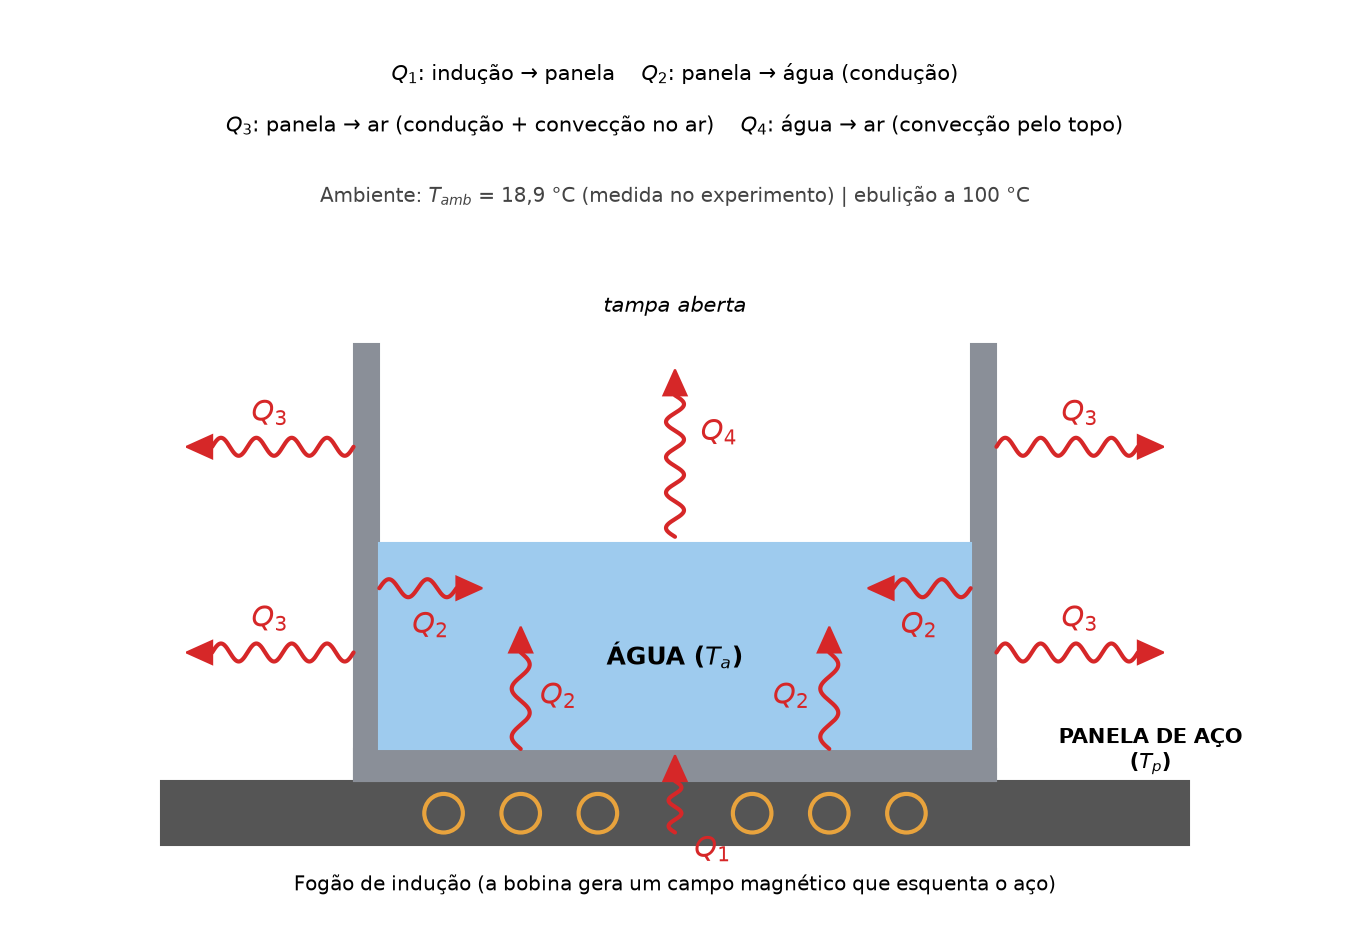

- `Q1 = P*efi`: o fogão de indução esquenta a panela
- `Q2 = (Tp-Ta)/R3`: calor da panela para a água (condução na parede)
- `Q3 = (Tp-Tamb)/(R1+R2)`: calor da panela para o ar (condução na parede + convecção no ar)
- `Q4 = (Ta-Tamb)/R4`: calor da água para o ar pela superfície (convecção)

## Diagrama de estoques e fluxos

Dois estoques de energia: a panela (`Up`) e a água (`Ua`).

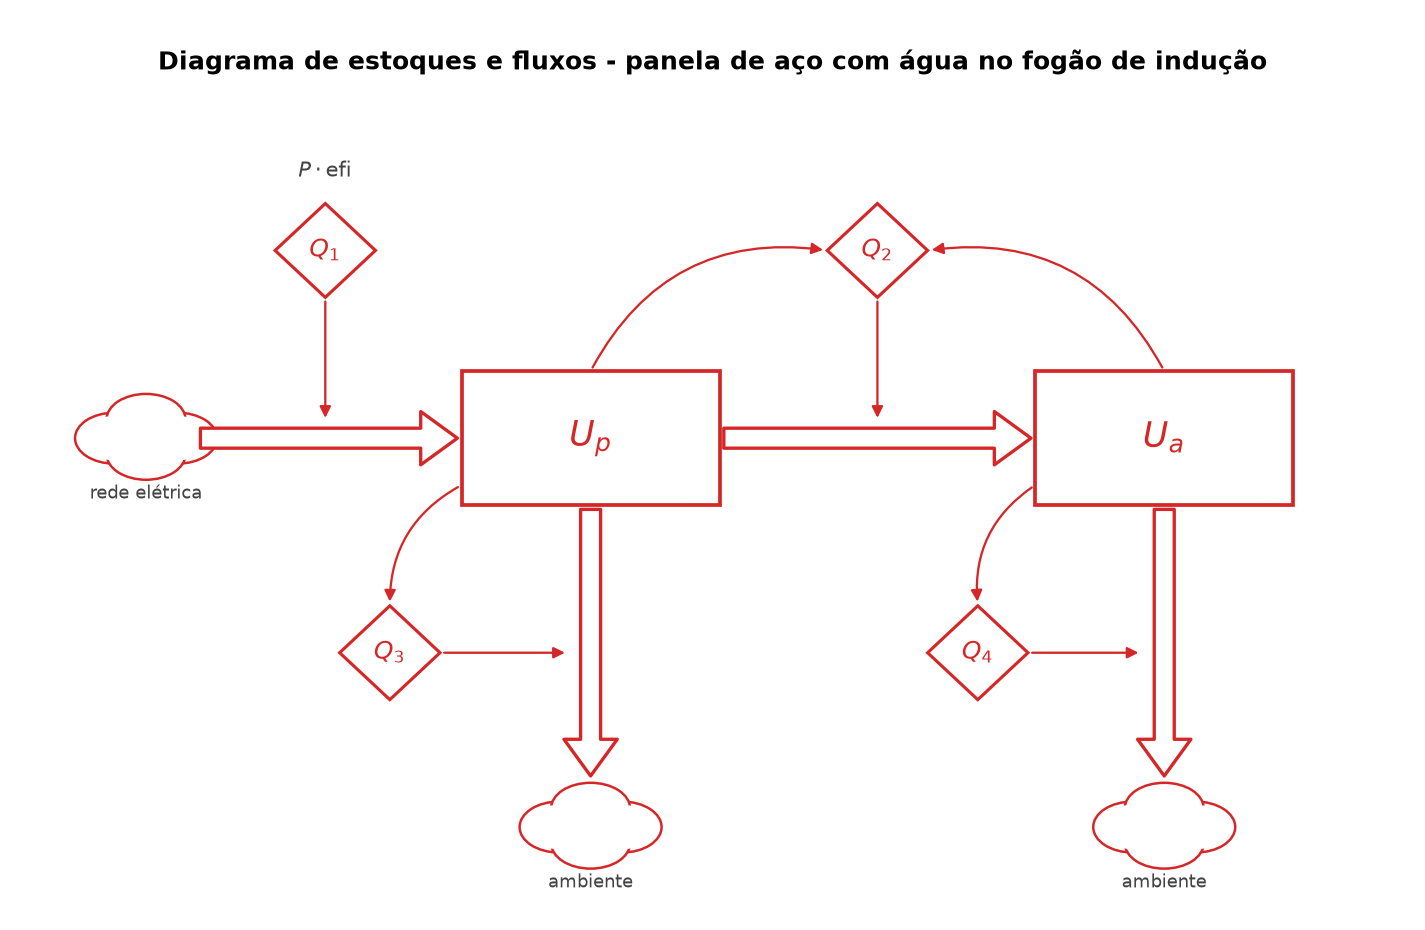

- `dUpdt = Q1 - Q2 - Q3` → `dTp/dt = (Q1 - Q2 - Q3)/(mp*cp)`
- `dUadt = Q2 - Q4` → `dTa/dt = (Q2 - Q4)/(ma*ca)`

In [2]:
#parametros

mp = 0.75
cp = 500
ma = 1.123
ca = 4186
har = 60
r = 0.08
H = 0.0812

Apanelaaberta = (np.pi*r**2)
h_agua = (ma / 1000) / Apanelaaberta
Aplateral = (2*np.pi*r*H)
Ap = (2*np.pi*r*h_agua+Apanelaaberta)

Kaco = 16
d = 0.00054
P = 200        
efi = 0.85
Tamb = 18.9

In [3]:
#modelo

R1 = 1 / (har * Aplateral)
R2 = (d / 2) / (Kaco * Aplateral)
R3 = (d / 2) / (Kaco * Ap)
R4 = 1 / (har * Apanelaaberta)



def modelo_a(x, t):
    Tp = x[0]
    Ta = x[1]  
    Q1 = P*efi
    Q2 = ((Tp-Ta)/ (R3))
    Q3 = ((Tp-Tamb)/ (R1+R2))
    Q4 = ((Ta-Tamb)/ (R4))
    dUpdt = (1/(mp*cp)) * (Q1-Q2-Q3)
    dUadt = (1/(ma*ca)) * (Q2-Q4)
    dydt = [dUpdt, dUadt]
    return dydt

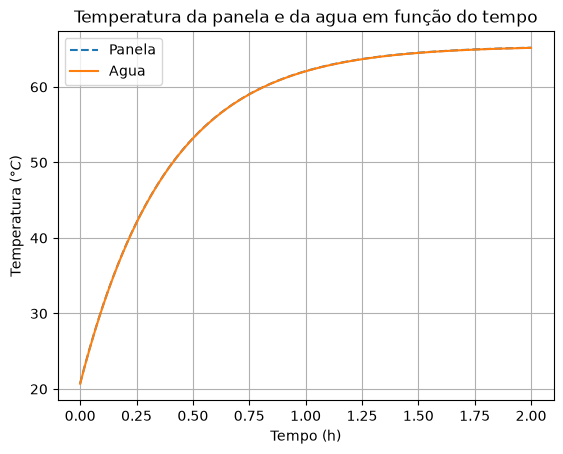

In [4]:
# modelo implementacao

Tp0 = 20.7
Ta0 = 20.7
x0 = [Tp0, Ta0]

dt = 1
tempo = np.arange(0, 7200+dt, dt)
tempo_grafico = tempo / 3600

x_lista = odeint(modelo_a, x0,tempo)
Tp_lista = x_lista[:,0]
Ta_lista = x_lista[:,1]

plt.plot(tempo_grafico, Tp_lista, '--', label='Panela')
plt.plot(tempo_grafico, Ta_lista, label='Agua')
plt.legend()
plt.title('Temperatura da panela e da agua em função do tempo')
plt.xlabel('Tempo (h)')
plt.ylabel('Temperatura ($°C$)')
plt.grid()
plt.show()

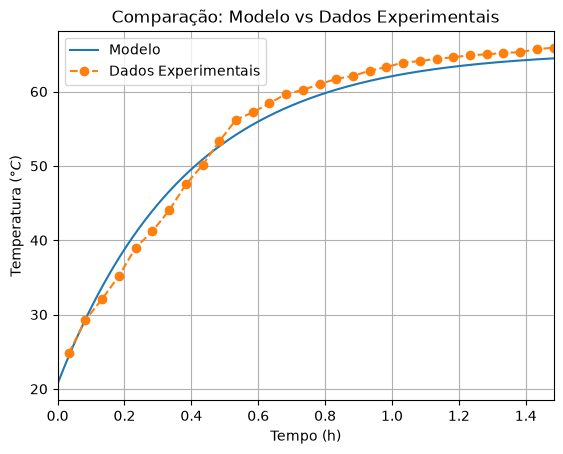

In [5]:
# validacao

temperatura_exp = [21.1, 21.9, 24.8, 29.3, 32.1, 35.2, 
            39, 41.2, 44, 47.5, 50.1, 53.3, 56.2, 57.2, 58.4, 
            59.7, 60.2, 61, 61.7, 62.1, 62.8, 63.3, 63.9, 64.1, 
            64.4, 64.6, 64.9, 65, 65.2, 65.3, 65.7, 65.9]

dt = 3
tempo_medido = np.arange(3, 96 + dt, dt)   # tempos anotados no cronometro (min)
atraso = 7                                 # o cronometro comecou 7 min antes do fogao aquecer a agua
tempo_exp = tempo_medido - atraso          # tempo desde o inicio do aquecimento (min)

# os 2 primeiros pontos (3 e 6 min no cronometro) sao de antes do aquecimento -> descartados
tempo_exp = tempo_exp[2:]
temperatura_exp = temperatura_exp[2:]

tempo_exp = tempo_exp / 60

plt.title("Comparação: Modelo vs Dados Experimentais")
plt.plot(tempo_grafico, Ta_lista, label='Modelo')
plt.plot(tempo_exp, temperatura_exp, '--o', label='Dados Experimentais')
plt.xlabel("Tempo (h)")
plt.ylabel("Temperatura ($°C$)")
plt.grid(True)
plt.legend()
plt.xlim(0, max(tempo_exp))
plt.show()

In [6]:
# erro medio

tempo_validacao = np.array(tempo_exp)
tempo_validacao = tempo_validacao*3600
tempo_validacao = np.insert(tempo_validacao, 0, 0)   # o odeint precisa comecar em t = 0 (condicao inicial)

x_validacao = odeint(modelo_a, x0, tempo_validacao)
Ta_validacao = x_validacao[1:, 1]                    # tira o t = 0

lista_erros = []

i = 0
while i < len(temperatura_exp):
    erro = abs((Ta_validacao[i] - temperatura_exp[i]) / temperatura_exp[i]) * 100

    lista_erros.append(erro)
    i = i + 1

erro_medio = np.mean(lista_erros)

print(f'Erro percentual médio: {erro_medio:.2f}%')

Erro percentual médio: 2.78%


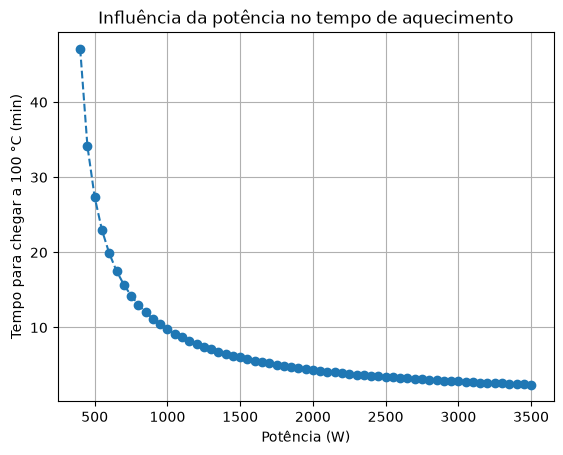

In [7]:
# grafico conclusivo

tempos_100 = []

def tempo100(tempo, Ta_lista):
    i = 0
    while i < len(tempo):
        if Ta_lista[i] >= 100:
            return tempo[i]
        i = i + 1

    return np.nan


P_lista = np.arange(100, 3500 + 50, 50)

def modelo_b(x, t, P):
    Tp = x[0]
    Ta = x[1]  
    Q1 = P*efi
    Q2 = ((Tp-Ta)/ (R3))
    Q3 = ((Tp-Tamb)/ (R1+R2))
    Q4 = ((Ta-Tamb)/ (R4))
    dUpdt = (1/(mp*cp)) * (Q1-Q2-Q3)
    dUadt = (1/(ma*ca)) * (Q2-Q4)
    dydt = [dUpdt, dUadt]
    return dydt

dt = 1
tempo = np.arange(0, 7200+dt, dt)

for P in P_lista:
    x_lista = odeint(modelo_b, x0, tempo, args=(P,))
    Ta_lista = x_lista[:,1]
    tempos_100.append(tempo100(tempo, Ta_lista)/60)

plt.plot(P_lista, tempos_100, '--o')
plt.xlabel('Potência (W)')
plt.ylabel('Tempo para chegar a 100 °C (min)')
plt.title('Influência da potência no tempo de aquecimento')
plt.grid()
plt.show()